# TP4: Denoiseing In The STFT Domain
## Autor: Volodya ALEKSANYAN

**Goal**: #TODO j'écris après

## Course Notes

### Short-Time Fourier Transform (STFT)

Perform a local spectral analyysis of te signal.

Let $w(t)$ to be a smooth window localized around $t=0$. Let the time-frequency atom :
$$\phi_{\tau, \nu}(t) = w(t-\tau)e^{i2\pi \nu t}$$
The TF transform of a signal computes its correlation with TF atom $\phi_{\tau, \nu}(t)$:
$$X(\tau, \nu) = \langle x(t), \phi_{\tau, \nu}(t) \rangle = \int_{-\infty}^{\infty} x(t) w(t-\tau)e^{-i2\pi \nu t} dt$$

Parameters are :
- the lenght and shape of the window
- redundancy of the time and frequency

### Discrete STFT
- let $x\in \mathbb{R}^T$ be signal and let $w\in \mathbb{R}^L$ be a window. The DSTFT is :
$$X[\tau, \nu] = \sum_{t=0}^{N-1} x[t] w[t-\tau] e^{-i2\pi \nu t/M}$$
$\alpha >= 1$ control the redundancy of the time and $M>=N$ controls the frequency, usually $M=L$ or $M=2L$.

All the TF coefficients $X[\tau, \nu]$ can be computed by the analysis operator: $\Phi: X = \Phi^*x$ 

### Discrete Inverse STFT
We do not have in general:

$$x[t] = \sum_{\tau, \nu} X[\tau, \nu] w[t-\alpha \tau] e^{i2\pi \nu t/M}$$

or $$x \neq \Phi\Phi^* x$$

The invert of a Gabor dictionary $\Phi$ is obtained by canonical dual frame $\tilde{\Phi}$ :
$$x[t] = \sum_{\tau, \nu} X[\tau, \nu] \tilde{w}[t-\alpha \tau] e^{i2\pi \nu t/M}$$

where $\tilde{w}$ is the dual window of $w$.

Or in matrix form: $$x = \tilde{\Phi}\Phi^*x = \Phi\tilde{\Phi}^*x$$

### Syntesis Operation
$$x[t] = \sum_{\tau, \nu} \tilde{X}[\tau, \nu] w[t - a\tau] e^{i 2πν/M t}$$

With $\tilde{X} = \tilde{\Phi}^*x$ : $x = \Phi\tilde{X}$

Néanmoins, it exists an infinity of synthesis coefs $\alpha$ such that
$x = \Phi\alpha$

/!\\
In some implementations, the "invert" operator is the "synthesis" operation and must be performed with the appropriate dual
window

/!\\ It is more useful to have access to the "synthesis" operator rather than the actual invert operator

### To Choose Parameters /!\\

Heisenberg's uncertainty principle states that a signal cannot be both well localized in time AND in frequency. The consequence is that short windows are more adapted to "transient", and long windows to "tonal", "stationary", parts of the signal

Common choices for a high-delity audio signal with a sampling frequency of 44.1 kHz with a window of size L are:
- Shape of the window: Hann, Hamming, Gaussian
- Length of the window: between 256 samples to 4096 samples. Common choice: 1024 samples
- Redundancy in time: overlap of 50% or 75% between two consecutive window
- Redundancy in frequency: FFT of size L or 2L

### Denoiz in the Time-Frequency Domain

Let $y$ be a noisy measure of a "clea" signal $x$ corrupted by some additive noise $n$:
$$y = x + n$$
In the STFT domain, we have:
$$Y[\tau, \nu] = X[\tau, \nu] + N[\tau, \nu]$$
$$E\left[|Y[\tau, \nu]|^2\right] = |X[\tau, \nu]|^2 + S_n[\nu]$$

And the proposed estimator:

- Hard Thresholding: 

$$X(\tau, \nu) = \begin{cases} Y[\tau, \nu] & \text{if } |Y[\tau, \nu]| > \lambda |S_n[\nu]| \\ 0 & \text{otherwise} \end{cases}$$

- Spectral Substraction:

$$X(\tau, \nu) = Y[\tau, \nu]\left(1 - \frac{\lambda^2 |S_n[\nu]|^2}{|Y[\tau, \nu]|^2}\right)^+$$

---

## Denoising

STFT with a Hann window of 1024 samples (64 ms at 16 kHz) and 75% overlap (as advised in the courser).

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal

In [8]:
# Utils as always
def load_wav(path):
    """Load a wav file as float in [-1, 1], with the mean removed."""
    fs, x = wavfile.read(path)
    x = x.astype(float) / 32768
    return fs, x - x.mean()

def snr(x, y):
    return 20 * np.log10(np.linalg.norm(x) / np.linalg.norm(x - y))

def mix(x, n, snr_db):
    """
    Scale the noise n so that SNR(x+n | x) = snr_db. 
    Returns the noisy signal and the scaled noise.
    """
    n = n * np.linalg.norm(x) / np.linalg.norm(n) * 10**(-snr_db / 20)
    return x + n, n

L = 1024        # Hann window lengt
HOP = L // 4    #75% overlap

def stft(x):
    return signal.stft(x, fs, 'hann', L, L - HOP)[2]

def istft(X, n):
    return signal.istft(X, fs, 'hann', L, L - HOP)[1][:n]

In [9]:
fs, x = load_wav('../data/music.wav')
names = ["noise1", "noise2", "noise3"]
noises = {name: load_wav(f'../data/{name}.wav')[1] for name in names}

In [11]:
print(f'music: fs={fs}Hz, len: {len(x) / fs:.2f}s')
print(f'exact reconstruction Error: {np.abs(istft(stft(x), len(x)) - x).max():.1e}')

music: fs=16000Hz, len: 8.75s
exact reconstruction Error: 5.6e-16


### Noise level and estimators

$|Y|$ is our amplitude while $S_n[\nu]$ is a power, thus we compare $|Y|$ with $\sigma_n[\nu] = \sqrt{S_n[\nu]}$. 

We estimate $S_n[\nu]$ by taking the mean of $|N[\tau, \nu]|^2$ over the frames of the noise alone.

Nota bene:We are using the noise here directly as we have it, otherwise we could have use a "slient" par of the recording that would give only the noise normally/

In [12]:
def noise_level(n):
    """sigma_n[nu] = sqrt(S_n[nu]): mean of |N[tau, nu]|^2 over the frames, then the root. Shape (freq, 1)."""
    return np.sqrt((np.abs(stft(n))**2).mean(axis=1, keepdims=True))

def hard_threshold(Y, sigma, lam):
    return Y * (np.abs(Y) > lam * sigma)

def spectral_subtraction(Y, sigma, lam):
    return Y * np.maximum(1 - lam**2 * sigma**2 / np.maximum(np.abs(Y)**2, 1e-20), 0)

methods = {'Hard thresholding': hard_threshold, 'Spectral subtraction': spectral_subtraction}

### Choosing $\lambda$

For each noise and each input SNR, we denoise for $\lambda$ from 0 to 6 and measure the SNR of the result against the clean music.

In [13]:
def choose(lams, scores, tol=0.5):
    """
    Smallest lambda whose SNR is less than tol dB under the maximum.
    that was a suggestion from M. Kowalski
    """
    return lams[np.argmax(scores >= scores.max() - tol)]

lams = np.linspace(0, 6, 61)
snrs_in = [0, 5, 10, 15]
curves = {}                 # curves[noise, method, snr_in] = output SNR for each lambda

for name in names:
    for s in snrs_in:
        y, n = mix(x, noises[name], s)
        Y, sigma = stft(y), noise_level(n)
        for m, f in methods.items():
            curves[name, m, s] = np.array([snr(x, istft(f(Y, sigma, lam), len(x))) for lam in lams])

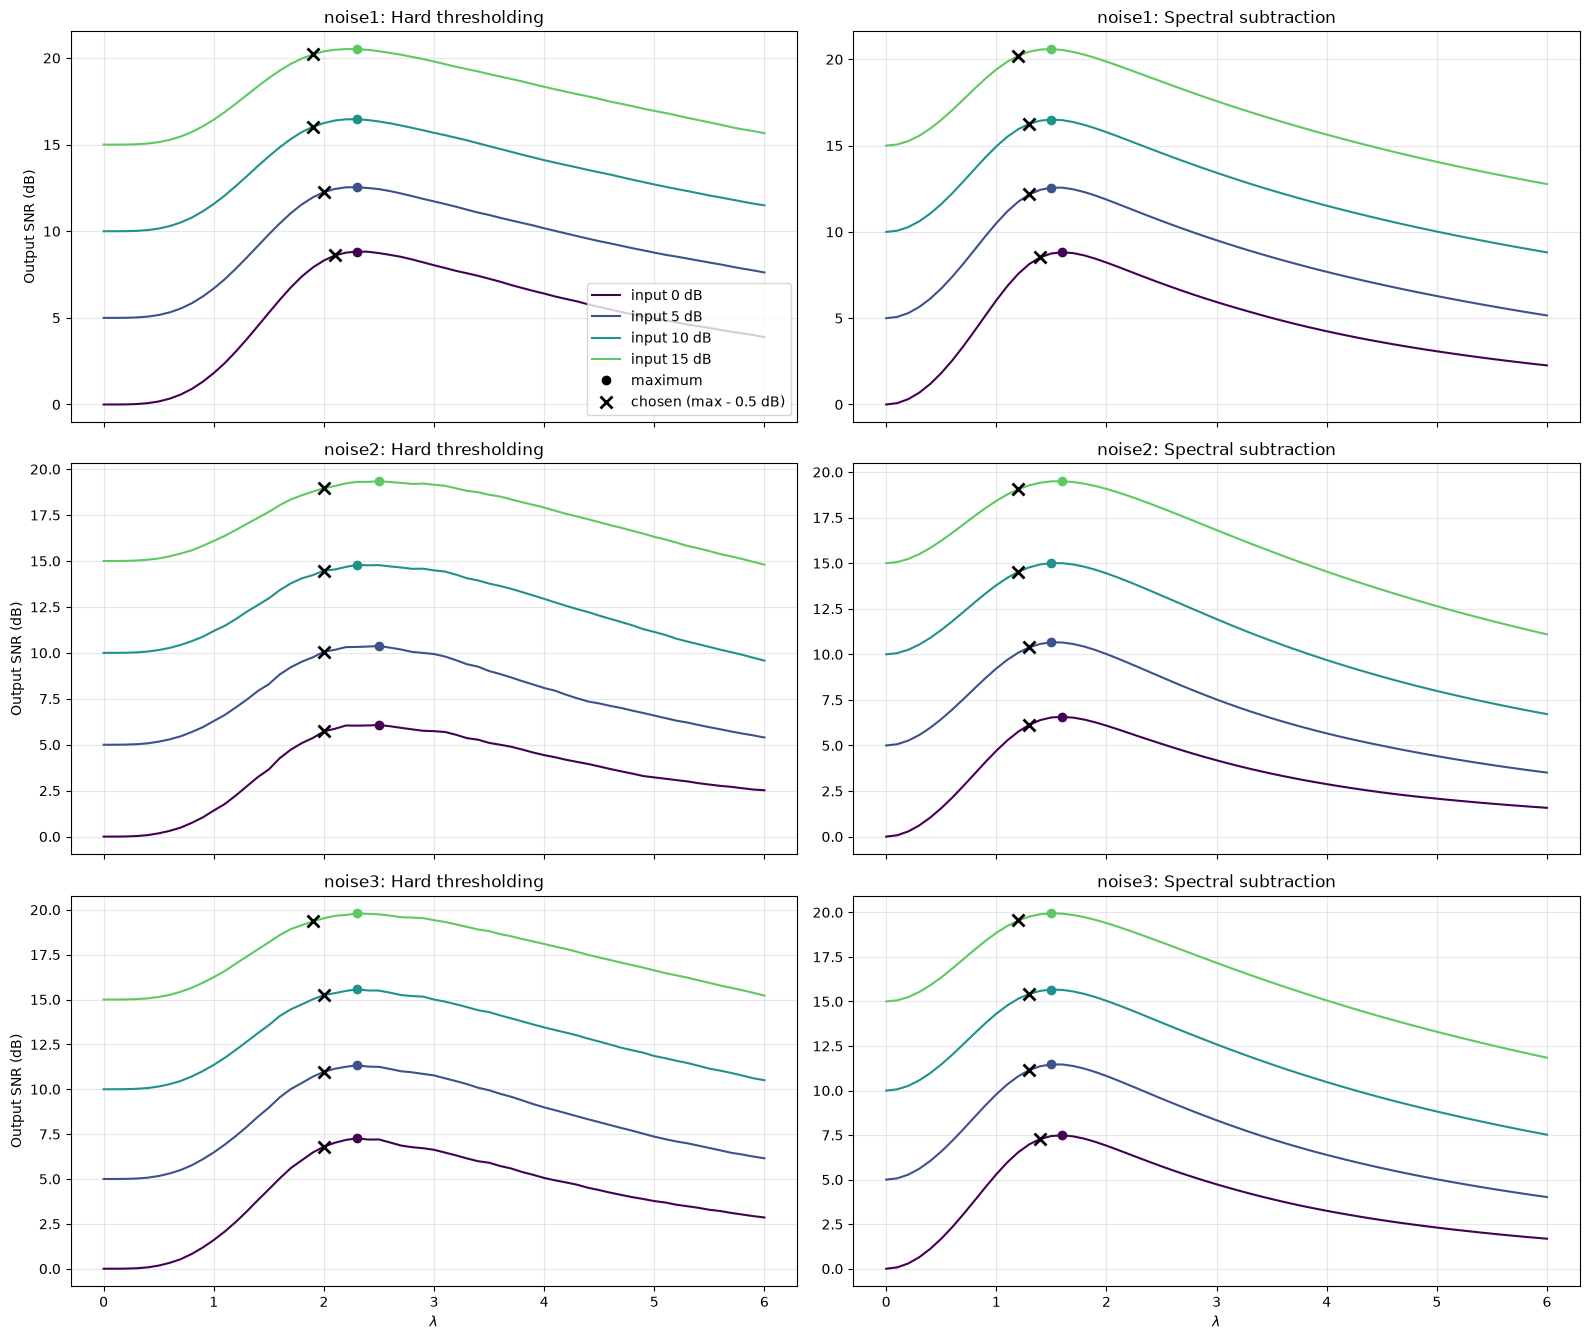

In [14]:
fig, ax = plt.subplots(len(names), len(methods), figsize=(16, 4.5 * len(names)), sharex=True)
for i, name in enumerate(names):
    for j, m in enumerate(methods):
        a = ax[i, j]
        for s in snrs_in:
            c = curves[name, m, s]
            color = plt.cm.viridis(s / 20)
            a.plot(lams, c, color=color, label=f'input {s} dB')
            a.plot(lams[np.argmax(c)], c.max(), 'o', color=color)
            lam_c = choose(lams, c)
            a.plot(lam_c, c[lams == lam_c], 'x', color='k', ms=8, mew=2)
        a.set_title(f'{name}: {m}')
        a.grid(alpha=0.3)
    ax[i, 0].set_ylabel('Output SNR (dB)')
for a in ax[-1]:
    a.set_xlabel(r'$\lambda$')
ax[0, 0].plot([], [], 'ko', label='maximum')
ax[0, 0].plot([], [], 'kx', ms=8, mew=2, label='chosen (max - 0.5 dB)')
ax[0, 0].legend(loc='lower right')
plt.tight_layout()
plt.show()

In [17]:
print('noise \t method \t\t input \t lambda max -> SNR \tlambda chosen -> SNR')
for (name, m, s), c in curves.items():
    lam_c = choose(lams, c)
    print(f'{name}   {m:21s}  {s:3d} dB   {lams[np.argmax(c)]:4.1f} -> {c.max():5.2f} dB     {lam_c:4.1f} -> {c[lams == lam_c][0]:5.2f} dB')

noise 	 method 		 input 	 lambda max -> SNR 	lambda chosen -> SNR
noise1   Hard thresholding        0 dB    2.3 ->  8.83 dB      2.1 ->  8.61 dB
noise1   Spectral subtraction     0 dB    1.6 ->  8.82 dB      1.4 ->  8.53 dB
noise1   Hard thresholding        5 dB    2.3 -> 12.54 dB      2.0 -> 12.26 dB
noise1   Spectral subtraction     5 dB    1.5 -> 12.56 dB      1.3 -> 12.18 dB
noise1   Hard thresholding       10 dB    2.3 -> 16.47 dB      1.9 -> 16.03 dB
noise1   Spectral subtraction    10 dB    1.5 -> 16.51 dB      1.3 -> 16.27 dB
noise1   Hard thresholding       15 dB    2.3 -> 20.51 dB      1.9 -> 20.21 dB
noise1   Spectral subtraction    15 dB    1.5 -> 20.59 dB      1.2 -> 20.21 dB
noise2   Hard thresholding        0 dB    2.5 ->  6.07 dB      2.0 ->  5.73 dB
noise2   Spectral subtraction     0 dB    1.6 ->  6.57 dB      1.3 ->  6.14 dB
noise2   Hard thresholding        5 dB    2.5 -> 10.37 dB      2.0 -> 10.06 dB
noise2   Spectral subtraction     5 dB    1.5 -> 10.66 dB      1.

à $\lambda = 0$ rien n'est enlevé, donc le SNR de sortie est égale au SNR d'entrée. Quand $\lambda$ est grand, la musique se coupe aussi et le SNR diminue. Le maximum est entre: $\lambda \approx 2.3$ for hard thresholding et $\lambda \approx 1.5$ pour spectral subtraction, pour chaque bruit et chaque niveau d'entrée.

La courbe a besoin du signal propre $x$, et c'est un *oracle* en fait. Ca nous dit où est-ce que le $\lambda$ devreait être, même si en réalité on peut pas le calculer.

**On ne prends pas le maximum mais juste un peu avant** ! En effet, la courbe est plate sur le sommet donc aller un peu en dessous du maximum (0.5 dB) donne un $\lambda$ légèrement plus petit. Le SNR mesure l'énergie globale, dominé par les notes fortes. Les parties silencieuses de la musique ne compte pas vraiment dedans, néanmoins elles sont les paramètres les plus sensibles du seuil. Un $\lambda$ légèrement plus petit les conserve pour presque perte de SNR.